# Carbon Tracking — Medical (UCI HAR) Per-Model Analysis (live measurements)

Re-runs the canonical arch/loss combinations from the **medical training sweep**
(`experiment_training_medical_final.ipynb`) with **CarbonTracker + CodeCarbon +
the Electricity Maps API attached live**, then produces per-model carbon charts.

This is the medical-dataset twin of the North Sea
`[np]carbon_tracking.ipynb`. Same tracking strategy; different dataset, different
evaluation metric.

| North Sea carbon nb | This notebook (medical) |
|---|---|
| Google Colab + Drive (`/content/drive`) | GCP Vertex AI Workbench VM (`/home/jupyter`) |
| `depth` / `nodepth` `.npz` variants | single `har_transition/` dataset |
| `recall_tops` + `Predicted_well_depth_npd` | `evaluate_medical` |
| primary metric: `recall` (formation tops) | primary metric: `transition_recall` |
| grid pinned to **Norway (NOR)** | grid **auto-detected** from the VM's GCP region |

**Inputs (read-only):** `experiment_log_medical__shard*.csv` — used only to show the
sweep's original `transition_recall` next to the new carbon numbers. The notebook
runs fine without them.

**Choose what gets compared in the USER CONFIG cell** (right after imports);
everything downstream consumes that single block.

> **Variant: SEPARATE** — training and inference are measured by two independent CodeCarbon trackers, so their emissions are reported distinctly. See the `_combined` notebook for a single train+inference figure.

In [1]:
# Carbon libraries only — fastai/tsai/torch already ship in the Workbench image.
import sys, subprocess
def _pip(*args):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=False)

_pip("carbontracker")
_pip("-U", "codecarbon")   # need >=3.0 for OfflineEmissionsTracker(country_iso_code=...)
print("carbon libs ready (restart the kernel once if codecarbon was upgraded)")

carbon libs ready (restart the kernel once if codecarbon was upgraded)


In [2]:
import os, sys as _sys, gc as _gc, socket, subprocess, uuid, re, time, json as _json
from pathlib import Path
from datetime import datetime
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── Locate the CRP repo root so `geoxts` imports cleanly on the VM ──────────
# On the VM geoxts is usually already importable; this just makes the notebook
# robust to being launched from anywhere under the repo. No Google Drive paths.
def _repo_root():
    p = Path.cwd().resolve()
    for parent in [p] + list(p.parents):
        if (parent / "setup.py").is_file() and (parent / "geoxts").is_dir():
            return parent
    return None
REPO_ROOT = _repo_root()
if REPO_ROOT is not None and str(REPO_ROOT) not in _sys.path:
    _sys.path.insert(0, str(REPO_ROOT))

from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
import seaborn as sns

from fastai.learner import Learner
from fastai.metrics import accuracy
from fastai.callback.core import Callback
from fastai.callback.tracker import EarlyStoppingCallback, SaveModelCallback
from fastai.losses import CrossEntropyLossFlat, FocalLossFlat, LabelSmoothingCrossEntropyFlat

from geoxts.benchmark_models import (
    build_model, count_parameters, random_seed,
    LSTM_2dCNN, LSTM_XCM, XCM_LSTM, LSTM_FCN_2dCNN,
)
from tsai.all import TSDatasets, TSDataLoaders, Categorize, combine_split_data
from tsai.all import FCN, LSTM, XCM, LSTM_FCN

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from carbontracker.tracker import CarbonTracker
from codecarbon import OfflineEmissionsTracker

# Deterministic CUDA so this notebook reproduces the sweep's metrics. Without
# these, cuDNN picks different conv algorithms per run and the same config can
# land anywhere on the leaderboard with no other code change.
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

MACHINE = socket.gethostname()
try:
    GIT_SHA = subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL
    ).decode().strip()
except Exception:
    GIT_SHA = "unknown"
print(f"REPO_ROOT      : {REPO_ROOT}")
print(f"CWD            : {Path.cwd()}")
print(f"Machine        : {MACHINE} | git: {GIT_SHA}")
print(f"CUDA available : {torch.cuda.is_available()}")
print("Deterministic CUDA mode enabled")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})

REPO_ROOT      : None
CWD            : /home/jupyter
Machine        : instance-20260325-155643-dsba-crp-clf | git: unknown
CUDA available : True
Deterministic CUDA mode enabled


## ⚙️ USER CONFIG — edit this cell to choose what gets compared

Every chart below is built from this single cell. The defaults mirror the
**medical sweep's 5 architectures / 6 arch-loss pairs** on the **`all_channels`**
subset, which keeps the carbon comparison apples-to-apples with
`experiment_training_medical_final.ipynb`.

In [3]:
# ── Where the dataset lives (produced by combined_data_split_medical.ipynb) ──
DATA_DIR = Path("har_transition")

# ── Canonical feature subset (one subset, comparable across architectures) ──
CANONICAL_SUBSET = "all_channels"   # 9 inertial channels

# ── Arch-loss pairs to carbon-track ─────────────────────────────────────────
# Exactly the ARCH_LOSS_PAIRS from the medical sweep, so the carbon numbers sit
# next to the metrics the colleague already has. Each pair gets its own bar.
ARCH_PLAN = [
    {"arch": "LSTM_2dCNN_default",     "loss": "cwl",   "lr_tag": "lr_fixed"},
    {"arch": "LSTM_FCN_default",       "loss": "cwl",   "lr_tag": "lr_fixed"},
    {"arch": "LSTM_XCM_default",       "loss": "cwl",   "lr_tag": "lr_fixed"},
    {"arch": "LSTM_XCM_default",       "loss": "focal", "lr_tag": "lr_fixed"},
    {"arch": "XCM_LSTM_default",       "loss": "cwl",   "lr_tag": "lr_fixed"},
    {"arch": "LSTM_FCN_2dCNN_default", "loss": "cwl",   "lr_tag": "lr_fixed"},
]

# Per-run label (arch + loss) — LSTM_XCM appears twice (cwl & focal), so the
# arch name alone is not unique; this label is what every chart's axis uses.
def _run_label(p): return f"{p['arch']}__{p['loss']}"
RUN_LABELS = [_run_label(p) for p in ARCH_PLAN]

# ── Training recipe (matches the medical sweep) ─────────────────────────────
COMMON_RECIPE = {
    "fixed_lr":             1e-3,
    "monitor":              "valid_loss",
    "early_stop_patience":  6,
    "early_stop_min_delta": 0.0,
    "n_epochs":             25,
    "batch_size":           25,
}

# ── Feature subset registry (channels of the medical dataset) ───────────────
# body_acc_x/y/z (0-2), body_gyro_x/y/z (3-5), total_acc_x/y/z (6-8)
FEATURE_SUBSETS_BY_NAME = {
    "all_channels":   ["body_acc_x", "body_acc_y", "body_acc_z",
                       "body_gyro_x", "body_gyro_y", "body_gyro_z",
                       "total_acc_x", "total_acc_y", "total_acc_z"],
    "body_acc_only":  ["body_acc_x", "body_acc_y", "body_acc_z"],
    "body_gyro_only": ["body_gyro_x", "body_gyro_y", "body_gyro_z"],
    "total_acc_only": ["total_acc_x", "total_acc_y", "total_acc_z"],
    "body_only":      ["body_acc_x", "body_acc_y", "body_acc_z",
                       "body_gyro_x", "body_gyro_y", "body_gyro_z"],
    "acc_only":       ["body_acc_x", "body_acc_y", "body_acc_z",
                       "total_acc_x", "total_acc_y", "total_acc_z"],
}

# ── Sanity checks ───────────────────────────────────────────────────────────
assert CANONICAL_SUBSET in FEATURE_SUBSETS_BY_NAME, "CANONICAL_SUBSET not in registry."
assert len(RUN_LABELS) == len(set(RUN_LABELS)), "Duplicate (arch, loss) pair in ARCH_PLAN."

print(f"Will carbon-track {len(ARCH_PLAN)} model(s) on subset "
      f"{CANONICAL_SUBSET!r} = {FEATURE_SUBSETS_BY_NAME[CANONICAL_SUBSET]}\n")
for p in ARCH_PLAN:
    print(f"  - {p['arch']:24s}  loss={p['loss']:6s}  lr={p['lr_tag']}")

Will carbon-track 6 model(s) on subset 'all_channels' = ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']

  - LSTM_2dCNN_default        loss=cwl     lr=lr_fixed
  - LSTM_FCN_default          loss=cwl     lr=lr_fixed
  - LSTM_XCM_default          loss=cwl     lr=lr_fixed
  - LSTM_XCM_default          loss=focal   lr=lr_fixed
  - XCM_LSTM_default          loss=cwl     lr=lr_fixed
  - LSTM_FCN_2dCNN_default    loss=cwl     lr=lr_fixed


In [4]:
# ── Dataset loader — identical contract to experiment_training_medical_final ──
def dataset_available():
    needed = [DATA_DIR / "train.npz", DATA_DIR / "val.npz",
              DATA_DIR / "test.npz",  DATA_DIR / "warm_state.json"]
    return all(p.exists() for p in needed)

def load_dataset():
    if not dataset_available():
        raise FileNotFoundError(
            f"Dataset not found in {DATA_DIR.resolve()}.\n"
            "Run combined_data_split_medical.ipynb first."
        )
    tr = np.load(DATA_DIR / "train.npz")
    vl = np.load(DATA_DIR / "val.npz")
    te = np.load(DATA_DIR / "test.npz")
    with open(DATA_DIR / "warm_state.json") as f:
        ws = _json.load(f)
    return {
        "X_train": tr['X'].astype(np.float32), "y_train": tr['y'].astype(np.int64),
        "X_val":   vl['X'].astype(np.float32), "y_val":   vl['y'].astype(np.int64),
        "X_test":  te['X'].astype(np.float32), "y_test":  te['y'].astype(np.int64),
        "PRED_COLUMN":   ws["PRED_COLUMN"],
        "MARKERS":       ws["MARKERS"],
        "FEATURES_GEOX": ws["FEATURES_GEOX"],
        "N_CLASSES":     ws["N_CLASSES"],
        "WINDOW_LEN":    ws["WINDOW_LEN"],
    }

print(f"{DATA_DIR}/: {'OK' if dataset_available() else 'MISSING — run combined_data_split_medical.ipynb first'}")

har_transition/: OK


In [5]:
# ── Evaluation — copied verbatim from experiment_training_medical_final.ipynb ──
# Primary metric: transition_recall (accuracy on label>0 windows), the medical
# analogue of North Sea recall_tops.
def evaluate_medical(learn, X_test, y_test, pred_column, batch_size=64):
    device = next(learn.model.parameters()).device
    X_t = torch.tensor(X_test, dtype=torch.float32)
    y_t = torch.tensor(y_test, dtype=torch.long)
    test_dl = DataLoader(TensorDataset(X_t, y_t), batch_size=batch_size,
                         shuffle=False, num_workers=0)
    learn.model.eval()
    all_preds, all_trues = [], []
    with torch.no_grad():
        for xb, yb in test_dl:
            logits = learn.model(xb.to(device))
            all_preds.extend(logits.argmax(dim=-1).cpu().numpy())
            all_trues.extend(yb.numpy())
    all_preds = np.array(all_preds); all_trues = np.array(all_trues)

    true_trans_mask = all_trues > 0
    pred_trans_mask = all_preds > 0
    if true_trans_mask.sum() > 0:
        t_recall = float((all_preds[true_trans_mask] == all_trues[true_trans_mask]).mean())
    else:
        t_recall = float('nan')
    if pred_trans_mask.sum() > 0:
        t_precision = float((all_trues[pred_trans_mask] > 0).mean())
    else:
        t_precision = float('nan')
    if not (np.isnan(t_recall) or np.isnan(t_precision)) and (t_recall + t_precision) > 0:
        t_f1 = 2 * t_precision * t_recall / (t_precision + t_recall)
    else:
        t_f1 = float('nan')

    n_classes = len(pred_column)
    if true_trans_mask.sum() > 0:
        f1_trans_only = float(f1_score(
            all_trues[true_trans_mask], all_preds[true_trans_mask],
            labels=list(range(1, n_classes)), average='macro', zero_division=0))
    else:
        f1_trans_only = float('nan')
    f1_mac  = float(f1_score(all_trues, all_preds, average='macro', zero_division=0))
    per_cls = f1_score(all_trues, all_preds, average=None, zero_division=0)

    if true_trans_mask.sum() > 0:
        abs_errors = np.abs(all_preds[true_trans_mask].astype(int) -
                            all_trues[true_trans_mask].astype(int))
        median_error    = float(np.median(abs_errors))
        max_class_error = float(np.max(abs_errors))
    else:
        median_error = float('nan'); max_class_error = float('nan')

    return {
        "transition_recall": t_recall, "transition_precision": t_precision,
        "transition_f1": t_f1, "f1_transition_only": f1_trans_only,
        "f1_macro": f1_mac, "median_error": median_error,
        "max_class_error": max_class_error, "per_class_f1": per_cls.tolist(),
        "all_preds": all_preds, "all_trues": all_trues,
    }

In [6]:
# ── Subset / dataloader / weight / loss helpers (from the medical sweep) ─────
def resolve_subset(subset_name, features_geox):
    names = FEATURE_SUBSETS_BY_NAME[subset_name]
    missing = [n for n in names if n not in features_geox]
    if missing:
        raise ValueError(f"Subset {subset_name!r} references unknown channels: {missing}")
    return [features_geox.index(n) for n in names], names

def build_dataloader(ds, subset_idx, batch_size):
    X_tr = ds["X_train"][:, subset_idx, :]
    X_vl = ds["X_val"][  :, subset_idx, :]
    X, y, splits = combine_split_data([X_tr, X_vl], [ds["y_train"], ds["y_val"]])
    dsets = TSDatasets(X, y, tfms=[None, [Categorize()]], splits=splits, inplace=True)
    dls = TSDataLoaders.from_dsets(dsets.train, dsets.valid, bs=batch_size,
                                   batch_tfms=[], num_workers=0)
    return dls, dls.valid, X_tr.shape

ENS_BETA = 0.999
def _weight_tensor(classes, weights):
    w = np.zeros(int(classes.max()) + 1, dtype=np.float32)
    for c, wt in zip(classes, weights): w[int(c)] = wt
    return torch.tensor(w, dtype=torch.float32)
def compute_class_weights(y):
    cl, ct = np.unique(y, return_counts=True)
    return _weight_tensor(cl, len(y) / (len(cl) * ct))
def compute_ens_weights(y):
    cl, ct = np.unique(y, return_counts=True)
    ens = (1 - ENS_BETA) / (1 - ENS_BETA ** ct); ens = ens / ens.min()
    return _weight_tensor(cl, ens)
def compute_sqrt_weights(y):
    cl, ct = np.unique(y, return_counts=True)
    w = np.sqrt(len(y) / (len(cl) * ct)); w = w / w.min()
    return _weight_tensor(cl, w)

def build_loss(loss_type, cwl, ens, sqrt, device):
    if loss_type == "ce":             return CrossEntropyLossFlat()
    elif loss_type == "cwl":          return CrossEntropyLossFlat(weight=cwl.to(device))
    elif loss_type == "cwl_sqrt":     return CrossEntropyLossFlat(weight=sqrt.to(device))
    elif loss_type == "ens":          return CrossEntropyLossFlat(weight=ens.to(device))
    elif loss_type == "focal":        return FocalLossFlat(gamma=2.0)
    elif loss_type == "focal_cwl":    return FocalLossFlat(gamma=2.0, weight=cwl.to(device))
    elif loss_type == "focal_ens":    return FocalLossFlat(gamma=2.0, weight=ens.to(device))
    elif loss_type == "label_smooth": return LabelSmoothingCrossEntropyFlat(eps=0.1)
    else: raise ValueError(f"Unknown loss_type={loss_type!r}")

# Architecture registry — the 5 architectures from the medical sweep.
ARCH_REGISTRY = {
    "LSTM_2dCNN_default":     (LSTM_2dCNN,     {}),
    "LSTM_XCM_default":       (LSTM_XCM,       {}),
    "LSTM_FCN_default":       (LSTM_FCN,       {}),
    "XCM_LSTM_default":       (XCM_LSTM,       {}),
    "LSTM_FCN_2dCNN_default": (LSTM_FCN_2dCNN, {}),
}
_missing = [p["arch"] for p in ARCH_PLAN if p["arch"] not in ARCH_REGISTRY]
if _missing:
    raise KeyError(f"ARCH_PLAN references {_missing} not in ARCH_REGISTRY.")
print(f"ARCH_REGISTRY has {len(ARCH_REGISTRY)} architectures; ARCH_PLAN selects {len(ARCH_PLAN)} run(s).")

ARCH_REGISTRY has 5 architectures; ARCH_PLAN selects 6 run(s).


## Build the run plan + cross-check with the sweep CSVs

Builds `CANONICAL_PLAN` (one entry per arch-loss pair), then loads any
`experiment_log_medical__shard*.csv` in the working directory and prints the
sweep's `transition_recall` for each combo as a baseline for the carbon re-run.

In [7]:
CANONICAL_PLAN = []
for entry in ARCH_PLAN:
    arch_label, loss_type, lr_tag = entry["arch"], entry["loss"], entry["lr_tag"]
    run_name = f"{arch_label}__{loss_type}__{CANONICAL_SUBSET}__{lr_tag}"
    CANONICAL_PLAN.append({
        "subset_name": CANONICAL_SUBSET, "arch_label": arch_label,
        "loss_type": loss_type, "lr_tag": lr_tag,
        "use_lr_find": (lr_tag == "lr_find"),
        "run_label": _run_label(entry), "run_name": run_name,
    })
print(f"Plan: {len(CANONICAL_PLAN)} runs")
for c in CANONICAL_PLAN:
    print(f"  - {c['run_name']}")

shard_files = sorted(Path(".").glob("experiment_log_medical__shard*.csv"))
if shard_files:
    df_sweep = pd.concat([pd.read_csv(p) for p in shard_files], ignore_index=True)
    if "lr_strategy" not in df_sweep.columns and "use_lr_find" in df_sweep.columns:
        df_sweep["lr_strategy"] = np.where(df_sweep["use_lr_find"], "lr_find", "lr_fixed")
    print(f"\nSweep CSVs: {len(df_sweep)} rows from {len(shard_files)} file(s).")
    print("Past transition_recall for the configured combos (baseline for the carbon re-run):")
    for c in CANONICAL_PLAN:
        m = df_sweep[(df_sweep["arch_label"] == c["arch_label"])
                   & (df_sweep["loss_type"]  == c["loss_type"])
                   & (df_sweep["subset_name"] == c["subset_name"])]
        if "lr_strategy" in df_sweep.columns:
            m = m[m["lr_strategy"] == c["lr_tag"]]
        if len(m) == 0:
            print(f"  ! NOT in sweep (first-time run): {c['run_name']}")
        else:
            print(f"  - {c['run_label']:34s}  recall(sweep)={m['transition_recall'].mean():.3f}  "
                  f"train_time={int(m['train_time_s'].mean()):4d}s  (n={len(m)})")
else:
    print("\nNo experiment_log_medical__shard*.csv found — proceeding without sweep baseline.")
    df_sweep = pd.DataFrame()

Plan: 6 runs
  - LSTM_2dCNN_default__cwl__all_channels__lr_fixed
  - LSTM_FCN_default__cwl__all_channels__lr_fixed
  - LSTM_XCM_default__cwl__all_channels__lr_fixed
  - LSTM_XCM_default__focal__all_channels__lr_fixed
  - XCM_LSTM_default__cwl__all_channels__lr_fixed
  - LSTM_FCN_2dCNN_default__cwl__all_channels__lr_fixed

Sweep CSVs: 72 rows from 1 file(s).
Past transition_recall for the configured combos (baseline for the carbon re-run):
  - LSTM_2dCNN_default__cwl             recall(sweep)=0.658  train_time=  18s  (n=1)
  - LSTM_FCN_default__cwl               recall(sweep)=0.892  train_time=   6s  (n=1)
  - LSTM_XCM_default__cwl               recall(sweep)=0.802  train_time=  11s  (n=1)
  - LSTM_XCM_default__focal             recall(sweep)=0.495  train_time=  10s  (n=1)
  - XCM_LSTM_default__cwl               recall(sweep)=0.838  train_time=  22s  (n=1)
  - LSTM_FCN_2dCNN_default__cwl         recall(sweep)=0.910  train_time=  17s  (n=1)


## Carbon tracker configuration

Same two-tracker strategy as the North Sea notebook:

- **CarbonTracker** → GPU only, pulls **live grid intensity** from the
  **Electricity Maps API** (same key) for the VM's geolocated region.
- **CodeCarbon** → CPU + GPU + RAM, pinned with
  `OfflineEmissionsTracker(country_iso_code=...)`.

Unlike the North Sea notebook (hard-pinned to `NOR`), the country here is
**auto-detected from the GCP metadata server** (instance zone → ISO3) so the
emission factor matches where the VM actually runs. Set
`CARBON_COUNTRY_ISO3_OVERRIDE` if you want to force a country (e.g. `"NOR"` to
make the numbers directly comparable to the North Sea study).

In [8]:
# ── Electricity Maps API key (same key as the North Sea notebook) ───────────
os.environ.setdefault("ELECTRICITYMAPS_API_KEY", "AwxzHHPcPQKUqeCzkweF")
_ct_api_keys = {"electricitymaps": os.environ["ELECTRICITYMAPS_API_KEY"]}

# ── Auto-detect the VM's country from the GCP metadata server ────────────────
# Returns ISO3 for CodeCarbon's OfflineEmissionsTracker. Maps the instance zone
# (e.g. "europe-west1-b") -> region -> country. Extend the map if your region is
# missing; falls back to "USA" with a printed warning.
CARBON_COUNTRY_ISO3_OVERRIDE = None   # e.g. "NOR" to force comparability w/ North Sea

_GCP_REGION_TO_ISO3 = {
    "us":                "USA", "northamerica-northeast": "CAN",
    "southamerica-east": "BRA", "southamerica-west": "CHL",
    "europe-west1":      "BEL", "europe-west2": "GBR", "europe-west3": "DEU",
    "europe-west4":      "NLD", "europe-west6": "CHE", "europe-west8": "ITA",
    "europe-west9":      "FRA", "europe-west10": "DEU", "europe-west12": "ITA",
    "europe-north1":     "FIN", "europe-central2": "POL",
    "europe-southwest1": "ESP", "asia-east1": "TWN", "asia-east2": "HKG",
    "asia-northeast1":   "JPN", "asia-northeast2": "JPN", "asia-northeast3": "KOR",
    "asia-south1":       "IND", "asia-south2": "IND", "asia-southeast1": "SGP",
    "asia-southeast2":   "IDN", "australia-southeast1": "AUS",
    "australia-southeast2": "AUS", "me-west1": "ISR", "me-central1": "QAT",
}

def _detect_gcp_zone():
    url = "http://metadata.google.internal/computeMetadata/v1/instance/zone"
    try:
        req = Request(url, headers={"Metadata-Flavor": "Google"})
        raw = urlopen(req, timeout=3).read().decode()
        return raw.split("/")[-1]   # e.g. "europe-west1-b"
    except Exception:
        return None

def _zone_to_iso3(zone):
    if not zone:
        return None
    region = "-".join(zone.split("-")[:-1])          # europe-west1-b -> europe-west1
    if region in _GCP_REGION_TO_ISO3:
        return _GCP_REGION_TO_ISO3[region]
    prefix = region.split("-")[0]                    # us-central1 -> us
    if prefix in _GCP_REGION_TO_ISO3:
        return _GCP_REGION_TO_ISO3[prefix]
    return None

_zone = _detect_gcp_zone()
if CARBON_COUNTRY_ISO3_OVERRIDE:
    CARBON_COUNTRY_ISO3 = CARBON_COUNTRY_ISO3_OVERRIDE
    print(f"Country pinned by override: {CARBON_COUNTRY_ISO3}")
else:
    CARBON_COUNTRY_ISO3 = _zone_to_iso3(_zone) or "USA"
    if _zone is None:
        print("[WARN] GCP metadata server unreachable — defaulting country to USA. "
              "Set CARBON_COUNTRY_ISO3_OVERRIDE if this VM is elsewhere.")
    elif _zone_to_iso3(_zone) is None:
        print(f"[WARN] zone={_zone!r} not in _GCP_REGION_TO_ISO3 — defaulting to USA. "
              "Add your region to the map for an accurate emission factor.")
    else:
        print(f"Detected GCP zone={_zone!r} -> CodeCarbon country={CARBON_COUNTRY_ISO3}")

CARBON_LOG_DIR = Path("carbon_logs_medical"); CARBON_LOG_DIR.mkdir(exist_ok=True)
MODEL_DIR      = Path("models_medical_carbon"); MODEL_DIR.mkdir(exist_ok=True)
LOG_PATH       = Path("experiment_log_medical__carbon_separate.csv")

class _CTCallback(Callback):
    def __init__(self, tracker): self.tracker = tracker
    def before_epoch(self):
        try: self.tracker.epoch_start()
        except Exception: pass
    def after_epoch(self):
        try: self.tracker.epoch_end()
        except Exception: pass

def _parse_carbontracker_log(log_dir, prefix):
    files = sorted(list(Path(log_dir).glob(f"{prefix}*carbontracker*.log")),
                   key=lambda p: p.stat().st_mtime, reverse=True)
    if not files:
        print(f"  [CT parse] No log files matched {prefix}*carbontracker*.log under {log_dir}")
        return float("nan"), float("nan")
    for path in files:
        text = path.read_text()
        for heading in ("Actual consumption", "Predicted consumption", "Final emissions", "Total"):
            m = re.search(heading + r".*?Energy:\s*([\d.eE+-]+)\s*kWh.*?(?:CO2eq|CO2):\s*([\d.eE+-]+)\s*g",
                          text, re.DOTALL | re.IGNORECASE)
            if m:
                return float(m.group(1)), float(m.group(2))
    text = files[0].read_text()
    kwh = re.findall(r"([\d.eE+-]+)\s*kWh", text)
    co2 = re.findall(r"([\d.eE+-]+)\s*g\s*(?:CO2eq|CO2|of\s*CO2)", text, re.IGNORECASE)
    if kwh and co2:
        print(f"  [CT parse] Fell back to last-number scan in {files[0].name}")
        return float(kwh[-1]), float(co2[-1])
    print(f"  [CT parse] No energy/emissions numbers found in {files[0].name}")
    return float("nan"), float("nan")

def _read_codecarbon_csv(path):
    if not Path(path).exists():
        return {"emissions_kg": float("nan"), "energy_kwh": float("nan"),
                "cpu_kwh": float("nan"), "gpu_kwh": float("nan"), "ram_kwh": float("nan"),
                "country": None, "region": None}
    r = pd.read_csv(path).iloc[-1]
    return {
        "emissions_kg": float(r.get("emissions", float("nan"))),
        "energy_kwh":   float(r.get("energy_consumed", float("nan"))),
        "cpu_kwh":      float(r.get("cpu_energy", float("nan"))),
        "gpu_kwh":      float(r.get("gpu_energy", float("nan"))),
        "ram_kwh":      float(r.get("ram_energy", float("nan"))),
        "country":      r.get("country_name", None),
        "region":       r.get("region", None),
    }
print(f"Carbon logs -> {CARBON_LOG_DIR}/   |   CodeCarbon country = {CARBON_COUNTRY_ISO3}")

Detected GCP zone='europe-west4-a' -> CodeCarbon country=NLD
Carbon logs -> carbon_logs_medical/   |   CodeCarbon country = NLD


In [9]:
# ── Dataset cache + per-combo driver ────────────────────────────────────────
_dataset_cache, _weight_cache = {}, {}
def _get_dataset():
    if "ds" not in _dataset_cache:
        ds = load_dataset()
        _dataset_cache["ds"] = ds
        y = ds["y_train"]
        _weight_cache["w"] = {"cwl": compute_class_weights(y),
                              "ens": compute_ens_weights(y),
                              "sqrt": compute_sqrt_weights(y)}
    return _dataset_cache["ds"], _weight_cache["w"]

def run_one_combo(combo):
    run_name    = combo["run_name"]
    arch_label  = combo["arch_label"]
    loss_type   = combo["loss_type"]
    subset_name = combo["subset_name"]
    use_lr_find = combo["use_lr_find"]
    print(f"\n=== RUN  {run_name} ===")
    random_seed(0, use_cuda=True)

    ds, weights = _get_dataset()
    subset_idx, subset_names = resolve_subset(subset_name, ds["FEATURES_GEOX"])
    R = COMMON_RECIPE
    dls, valid_dl, train_shape = build_dataloader(ds, subset_idx, R["batch_size"])
    lr_label = "lr_find" if use_lr_find else f"fixed {R['fixed_lr']}"
    print(f"  shape={train_shape}, loss={loss_type}, lr={lr_label}")

    arch_class, arch_kwargs = ARCH_REGISTRY[arch_label]
    model = build_model(arch_class, dls=dls, **arch_kwargs)
    device = next(model.parameters()).device
    loss_func = build_loss(loss_type, weights["cwl"], weights["ens"], weights["sqrt"], device)
    learn = Learner(dls, model, loss_func=loss_func, metrics=accuracy)

    if use_lr_find:
        try:
            lr_res = learn.lr_find(show_plot=False)
            lr = lr_res.valley if hasattr(lr_res, "valley") else float(lr_res)
        except Exception:
            lr = R["fixed_lr"]
    else:
        lr = R["fixed_lr"]

    cbs = [SaveModelCallback(monitor=R["monitor"]),
           EarlyStoppingCallback(monitor='valid_loss',
                                 min_delta=R["early_stop_min_delta"],
                                 patience=R["early_stop_patience"])]

    # ── TRAINING-scoped trackers (CarbonTracker GPU + CodeCarbon machine) ────
    cc = OfflineEmissionsTracker(
        country_iso_code=CARBON_COUNTRY_ISO3,
        project_name=f"medical_train_{run_name}",
        output_dir=str(CARBON_LOG_DIR),
        output_file=f"{run_name}_codecarbon.csv",
        measure_power_secs=5, tracking_mode="machine",
        log_level="error", save_to_file=True,
    )
    # monitor_epochs=1 + epochs_before_pred=1 makes CT log a result after the
    # first epoch (predicted) and again as "Actual" if training completes — so we
    # still get a number when early stopping fires before n_epochs.
    ct = CarbonTracker(
        epochs=R["n_epochs"], monitor_epochs=1, epochs_before_pred=1,
        log_dir=str(CARBON_LOG_DIR), log_file_prefix=run_name + "_",
        api_keys=_ct_api_keys or None, verbose=1, ignore_errors=True,
    )

    cc.start(); t0 = time.time(); cc_kg = np.nan
    try:
        learn.fit_one_cycle(R["n_epochs"], lr, cbs=cbs + [_CTCallback(ct)])
    finally:
        try: ct.stop()
        except Exception: pass
        try: cc_kg = cc.stop()
        except Exception: cc_kg = np.nan
    train_elapsed = time.time() - t0
    vals = learn.recorder.values[-1] if len(learn.recorder.values) else (np.nan, np.nan, np.nan)
    best_epoch = len(learn.recorder.values)

    model_path = MODEL_DIR / f"{run_name}.pth"
    torch.save(learn.model.state_dict(), model_path)

    # ── EVALUATION-scoped tracker (CodeCarbon only) ─────────────────────────
    # A second CodeCarbon tracker scopes the test-set evaluation on its own, so
    # training and eval emissions stay distinct. CarbonTracker is epoch-based and
    # doesn't fit a single inference pass, so eval is measured with CodeCarbon only.
    cc_eval = OfflineEmissionsTracker(
        country_iso_code=CARBON_COUNTRY_ISO3,
        project_name=f"medical_eval_{run_name}",
        output_dir=str(CARBON_LOG_DIR),
        output_file=f"{run_name}_codecarbon_eval.csv",
        measure_power_secs=5, tracking_mode="machine",
        log_level="error", save_to_file=True,
    )
    cc_eval.start(); eval_start = time.time()
    try:
        X_te_sub = ds["X_test"][:, subset_idx, :]
        metrics = evaluate_medical(learn, X_te_sub, ds["y_test"], ds["PRED_COLUMN"])
    finally:
        try: cc_eval.stop()
        except Exception: pass
    eval_elapsed = time.time() - eval_start
    print(f"  [eval] transition_recall={metrics['transition_recall']:.3f}  "
          f"f1_macro={metrics['f1_macro']:.3f}  median_err={metrics['median_error']:.2f}")

    # ── Parse tracker outputs ───────────────────────────────────────────────
    ct_kwh, ct_co2_g = _parse_carbontracker_log(CARBON_LOG_DIR, prefix=run_name + "_")
    cc_blob      = _read_codecarbon_csv(CARBON_LOG_DIR / f"{run_name}_codecarbon.csv")
    cc_eval_blob = _read_codecarbon_csv(CARBON_LOG_DIR / f"{run_name}_codecarbon_eval.csv")
    cc_kg = cc_blob["emissions_kg"] if not np.isnan(cc_blob["emissions_kg"]) else cc_kg

    # Training / eval / total CodeCarbon emissions in grams.
    cc_train_g = cc_kg * 1000 if (cc_kg is not None and not np.isnan(cc_kg)) else np.nan
    cc_eval_g  = cc_eval_blob["emissions_kg"] * 1000 if not np.isnan(cc_eval_blob["emissions_kg"]) else np.nan
    cc_total_g = np.nan if (np.isnan(cc_train_g) and np.isnan(cc_eval_g)) else np.nansum([cc_train_g, cc_eval_g])

    # ── Implied grid intensity (emissions / energy) for a sanity read ──────
    cc_implied = (cc_kg * 1000) / cc_blob["energy_kwh"] if (cc_blob["energy_kwh"] and cc_blob["energy_kwh"] > 0) else float("nan")
    ct_implied = ct_co2_g / ct_kwh if (not np.isnan(ct_kwh) and ct_kwh > 0) else float("nan")
    print(f"  [CC-train] country={cc_blob['country'] or CARBON_COUNTRY_ISO3!s:<10} "
          f"energy={cc_blob['energy_kwh']*1000:6.2f} Wh  emissions={cc_train_g:6.3f} g  "
          f"-> implied {cc_implied:6.1f} g/kWh")
    print(f"  [CC-eval ] energy={cc_eval_blob['energy_kwh']*1000:6.2f} Wh  "
          f"emissions={cc_eval_g:6.3f} g   |   [CC-total] {cc_total_g:6.3f} g")
    if np.isnan(ct_co2_g):
        print(f"  [CT] no parseable result (see [CT parse] warnings above)")
    else:
        print(f"  [CT] (GPU only, live grid, training) energy={ct_kwh*1000:6.2f} Wh  "
              f"emissions={ct_co2_g:6.3f} g  -> implied {ct_implied:6.1f} g/kWh")

    if not np.isnan(ct_co2_g) and not np.isnan(cc_kg) and (ct_co2_g + cc_kg * 1000) > 0:
        spread = 100.0 * abs(cc_kg * 1000 - ct_co2_g) / (0.5 * (ct_co2_g + cc_kg * 1000))
    else:
        spread = np.nan

    row = {
        "run_id": str(uuid.uuid4()), "run_name": run_name, "run_label": combo["run_label"],
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "machine": MACHINE, "git_sha": GIT_SHA,
        "subset_name": subset_name, "arch_label": arch_label, "loss_type": loss_type,
        "use_lr_find": use_lr_find, "lr_strategy": combo["lr_tag"], "lr": float(lr),
        "n_epochs": R["n_epochs"], "batch_size": R["batch_size"], "best_epoch": best_epoch,
        "total_params": int(count_parameters(model)),
        "train_loss": float(vals[0]) if vals[0] is not None else np.nan,
        "valid_loss": float(vals[1]) if vals[1] is not None else np.nan,
        "val_accuracy": float(vals[2]) if vals[2] is not None else np.nan,
        "transition_recall": metrics["transition_recall"],
        "transition_precision": metrics["transition_precision"],
        "transition_f1": metrics["transition_f1"],
        "f1_macro": metrics["f1_macro"], "f1_transition_only": metrics["f1_transition_only"],
        "median_error": metrics["median_error"], "max_class_error": metrics["max_class_error"],
        "per_class_f1": str(metrics["per_class_f1"]),
        "train_time_s": int(train_elapsed), "eval_time_s": int(eval_elapsed),
        "ct_energy_kwh":  float(ct_kwh) if not np.isnan(ct_kwh) else np.nan,
        "ct_emissions_g": float(ct_co2_g) if not np.isnan(ct_co2_g) else np.nan,
        # CodeCarbon — TRAINING scope
        "cc_emissions_kg": float(cc_kg) if cc_kg is not None else np.nan,
        "cc_emissions_g":  float(cc_train_g) if not np.isnan(cc_train_g) else np.nan,
        "cc_energy_kwh": cc_blob["energy_kwh"], "cc_cpu_kwh": cc_blob["cpu_kwh"],
        "cc_gpu_kwh": cc_blob["gpu_kwh"], "cc_ram_kwh": cc_blob["ram_kwh"],
        # CodeCarbon — EVALUATION scope
        "cc_eval_emissions_g": float(cc_eval_g) if not np.isnan(cc_eval_g) else np.nan,
        "cc_eval_energy_kwh": cc_eval_blob["energy_kwh"], "cc_eval_cpu_kwh": cc_eval_blob["cpu_kwh"],
        "cc_eval_gpu_kwh": cc_eval_blob["gpu_kwh"], "cc_eval_ram_kwh": cc_eval_blob["ram_kwh"],
        # CodeCarbon — TRAINING + EVALUATION total
        "cc_total_emissions_g": float(cc_total_g) if not np.isnan(cc_total_g) else np.nan,
        # Metadata
        "cc_country": cc_blob["country"], "cc_region": cc_blob["region"],
        "cc_implied_gpkwh": float(cc_implied), "ct_implied_gpkwh": float(ct_implied),
        "tracker_spread_pct": float(spread),
        "country_iso": cc_blob["country"] or CARBON_COUNTRY_ISO3,
        "model_path": str(model_path),
    }

    learn.model.cpu(); del learn, model, loss_func
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.ipc_collect()
    _gc.collect()
    return row
print("run_one_combo ready (training + evaluation tracked separately).")

run_one_combo ready (training + evaluation tracked separately).


## Run only the combos selected in USER CONFIG

A row is written to `experiment_log_medical__carbon_canonical.csv` after every
run, so partial progress survives a kernel disconnect.

In [10]:
all_rows = []
if not dataset_available():
    raise FileNotFoundError(f"{DATA_DIR}/ not found — run combined_data_split_medical.ipynb first.")
for combo_idx, combo in enumerate(CANONICAL_PLAN):
    print(f"\n[{combo_idx+1}/{len(CANONICAL_PLAN)}] {combo['run_name']}")
    try:
        row = run_one_combo(combo)
    except Exception as e:
        print(f"  RUN FAILED: {type(e).__name__}: {e}"); continue
    all_rows.append(row)
    df1 = pd.DataFrame([row])
    # Guard against schema drift: if an existing log has a different column set
    # (e.g. from an older notebook version), archive it instead of appending
    # ragged rows — that mismatch is what makes pd.read_csv raise a ParserError.
    if LOG_PATH.exists():
        with open(LOG_PATH) as _f:
            _hdr = _f.readline().rstrip("\n").split(",")
        if _hdr != list(df1.columns):
            _bak = LOG_PATH.with_name(f"{LOG_PATH.stem}__pre_{datetime.now():%Y%m%d_%H%M%S}.bak.csv")
            LOG_PATH.rename(_bak)
            print(f"  [log] schema changed — archived old log -> {_bak.name}")
    if LOG_PATH.exists():
        df1.to_csv(LOG_PATH, mode="a", header=False, index=False)
    else:
        df1.to_csv(LOG_PATH, mode="w", header=True, index=False)
    print(f"  -> wrote row to {LOG_PATH}")
print(f"\nDone. {len(all_rows)} runs logged to {LOG_PATH.resolve()}")


[1/6] LSTM_2dCNN_default__cwl__all_channels__lr_fixed

=== RUN  LSTM_2dCNN_default__cwl__all_channels__lr_fixed ===
  shape=(532, 9, 128), loss=cwl, lr=fixed 0.001


[codecarbon INFO @ 11:33:50] offline tracker init
[codecarbon WARNING @ 11:33:50] Multiple instances of codecarbon are allowed to run at the same time.


CarbonTracker: INFO - Detected CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
CarbonTracker: WARNING - No matching TDP found for CPU: Intel(R) Xeon(R) CPU @ 2.00GHz. Using average TDP of 35.61W at 50% utilization as fallback.
CarbonTracker: INFO - Using intensity provider: Electricity Maps API ('electricitymaps').
CarbonTracker: The following components were found: GPU with device(s) Tesla T4. CPU with device(s) Intel(R) Xeon(R) CPU @ 2.00GHz.


epoch,train_loss,valid_loss,accuracy,time
0,1.959002,1.938364,0.121739,00:02
1,1.919097,1.838479,0.156522,00:00
2,1.834728,1.683403,0.147826,00:00
3,1.731489,1.534847,0.208696,00:00
4,1.606226,1.391932,0.252174,00:00
5,1.492078,1.311148,0.243478,00:00
6,1.360175,1.276304,0.269565,00:00
7,1.264746,1.207166,0.295652,00:00
8,1.152663,1.136411,0.321739,00:00
9,1.073444,1.087667,0.356522,00:00


CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:49
	Energy:	0.001500995850 kWh
	CO2eq:	0.132087634823 g
	This is equivalent to:
	0.001236775607 km travelled by car
CarbonTracker: Average carbon intensity during training was 88.00 gCO2eq/kWh. 
CarbonTracker: 
Actual consumption for 1 epoch(s):
	Time:	0:00:02
	Energy:	0.000060039834 kWh
	CO2eq:	0.005283505393 g
	This is equivalent to:
	0.000049471024 km travelled by car
CarbonTracker: Finished monitoring.
Better model found at epoch 0 with valid_loss value: 1.9383636713027954.
Better model found at epoch 1 with valid_loss value: 1.838478684425354.
Better model found at epoch 2 with valid_loss value: 1.6834032535552979.
Better model found at epoch 3 with valid_loss value: 1.534847378730774.
Better model found at epoch 4 with valid_loss value: 1.391932487487793.
Better model found at epoch 5 with valid_loss value: 1.3111475706100464.
Better model found at epoch 6 with valid_loss value: 1.276304006576538.
Better model fou

epoch,train_loss,valid_loss,accuracy,time
0,1.804258,1.641267,0.330435,00:00
1,1.633495,1.311669,0.408696,00:00
2,1.459450,1.024675,0.347826,00:00
3,1.278632,0.822497,0.339130,00:00
4,1.102490,0.656659,0.452174,00:00
5,0.967149,0.588659,0.460870,00:00
6,0.829510,0.502723,0.539130,00:00
7,0.742007,0.488573,0.565217,00:00
8,0.665960,0.520659,0.539130,00:00
9,0.580170,0.416898,0.600000,00:00


... (5 outputs left out)

epoch,train_loss,valid_loss,accuracy,time
0,1.832079,1.788781,0.260870,00:00
1,1.660269,1.374461,0.278261,00:00
2,1.486838,1.031934,0.330435,00:00
3,1.313388,0.764617,0.521739,00:00
4,1.177475,0.674976,0.391304,00:00
5,1.048096,0.659738,0.504348,00:00
6,0.917655,0.585909,0.365217,00:00
7,0.820050,0.536803,0.513043,00:00
8,0.729120,0.478313,0.495652,00:00
9,0.668133,0.428903,0.556522,00:00


CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:22
	Energy:	0.000796188115 kWh
	CO2eq:	0.070064554099 g
	This is equivalent to:
	0.000656035151 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:22
	Energy:	0.000796188115 kWh
	CO2eq:	0.070064554099 g
	This is equivalent to:
	0.000656035151 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:22
	Energy:	0.000796188115 kWh
	CO2eq:	0.070064554099 g
	This is equivalent to:
	0.000656035151 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:22
	Energy:	0.000796188115 kWh
	CO2eq:	0.070064554099 g
	This is equivalent to:
	0.000656035151 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:22
	Energy:	0.000796188115 kWh
	CO2eq:	0.070064554099 g
	This is equivalent to:
	0.000656035151 km travelled by car
CarbonTracker: Average carbon intensity during training was 88.00 gCO2eq/kWh. 
Carbon

epoch,train_loss,valid_loss,accuracy,time
0,1.900083,1.775666,0.217391,00:00
1,1.737371,1.431933,0.269565,00:00
2,1.552563,1.151417,0.321739,00:00
3,1.372109,0.837432,0.347826,00:00
4,1.178202,0.656598,0.426087,00:00
5,1.001592,0.567220,0.434783,00:00
6,0.856879,0.526480,0.469565,00:00
7,0.754097,0.436791,0.565217,00:00
8,0.652602,0.427092,0.591304,00:00
9,0.567522,0.417607,0.573913,00:00


CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:21
	Energy:	0.000780194992 kWh
	CO2eq:	0.068657159279 g
	This is equivalent to:
	0.000642857297 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:21
	Energy:	0.000780194992 kWh
	CO2eq:	0.068657159279 g
	This is equivalent to:
	0.000642857297 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:21
	Energy:	0.000780194992 kWh
	CO2eq:	0.068657159279 g
	This is equivalent to:
	0.000642857297 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:21
	Energy:	0.000780194992 kWh
	CO2eq:	0.068657159279 g
	This is equivalent to:
	0.000642857297 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:21
	Energy:	0.000780194992 kWh
	CO2eq:	0.068657159279 g
	This is equivalent to:
	0.000642857297 km travelled by car
CarbonTracker: 
Predicted consumption for 25 epoch(s):
	Time:	0:00:21
	Energy:	0.0007

In [11]:
def _load_carbon_log(path):
    try:
        return pd.read_csv(path)
    except Exception as e:
        raise RuntimeError(
            f"{path.name} is not cleanly parseable ({e}). It likely mixes rows from "
            f"an older notebook version with a different column set. Fix: delete or "
            f"rename {path.name} and re-run the sweep, or just re-run THIS cell right "
            f"after the training-loop cell so it can use the in-memory `all_rows`."
        ) from e

# Prefer this session's in-memory rows (robust to a stale/ragged CSV on disk);
# fall back to the persistent log when running this cell in a fresh kernel.
if "all_rows" in dir() and len(all_rows):
    df_can = pd.DataFrame(all_rows)
    print(f"Using {len(df_can)} run(s) from this session's run loop (in memory).")
else:
    df_can = _load_carbon_log(LOG_PATH)
    print(f"Loaded {len(df_can)} run(s) from {LOG_PATH.name}.")

# Keep only rows matching the CURRENT USER CONFIG so older re-runs with a
# different config don't pollute today's charts.
_keep = (df_can["subset_name"] == CANONICAL_SUBSET) & df_can["run_label"].isin(RUN_LABELS)
df_can = df_can[_keep].copy()

# Grid sanity read: implied intensity should cluster around the detected country's
# annual factor. Rows far off usually mean CodeCarbon failed to pin the country.
if "cc_implied_gpkwh" not in df_can.columns:
    df_can["cc_implied_gpkwh"] = (df_can["cc_emissions_g"] / (df_can["cc_energy_kwh"] * 1000)) * 1000
print("Grid sanity (implied intensity per run):")
print(df_can[["run_label", "cc_country", "cc_implied_gpkwh"]].round(1).to_string(index=False))
print(f"\nCodeCarbon country pinned to: {CARBON_COUNTRY_ISO3}  "
      f"| CC-reported: {sorted(df_can['cc_country'].dropna().unique())}")

AGG_COLS = [c for c in [
    "ct_energy_kwh", "ct_emissions_g", "cc_energy_kwh", "cc_emissions_g",
    "cc_cpu_kwh", "cc_gpu_kwh", "cc_ram_kwh", "tracker_spread_pct",
    "cc_eval_energy_kwh", "cc_eval_emissions_g", "cc_total_emissions_g",
    "train_time_s", "eval_time_s", "best_epoch", "total_params",
    "transition_recall", "f1_macro", "median_error", "val_accuracy",
] if c in df_can.columns]
df = df_can.groupby(["run_label", "arch_label", "loss_type"], as_index=False)[AGG_COLS].mean()
df["n_runs_aggregated"] = (df_can.groupby(["run_label", "arch_label", "loss_type"])
                                 .size().reset_index(name="n")["n"].values)
# Preserve the USER CONFIG ordering for every chart.
df["__order"] = df["run_label"].map({lbl: i for i, lbl in enumerate(RUN_LABELS)})
df = df.sort_values("__order").drop(columns="__order").reset_index(drop=True)

print("\nPer-model measured carbon (cc_emissions_g = training; cc_eval_emissions_g = eval; cc_total_emissions_g = both):")
print(df.round(4).to_string(index=False))

Using 6 run(s) from this session's run loop (in memory).
Grid sanity (implied intensity per run):
                  run_label  cc_country  cc_implied_gpkwh
    LSTM_2dCNN_default__cwl Netherlands             267.6
      LSTM_FCN_default__cwl Netherlands             267.6
      LSTM_XCM_default__cwl Netherlands             267.6
    LSTM_XCM_default__focal Netherlands             267.6
      XCM_LSTM_default__cwl Netherlands             267.6
LSTM_FCN_2dCNN_default__cwl Netherlands             267.6

CodeCarbon country pinned to: NLD  | CC-reported: ['Netherlands']

Per-model measured carbon (cc_emissions_g = training; cc_eval_emissions_g = eval; cc_total_emissions_g = both):
                  run_label             arch_label loss_type  ct_energy_kwh  ct_emissions_g  cc_energy_kwh  cc_emissions_g  cc_cpu_kwh  cc_gpu_kwh  cc_ram_kwh  tracker_spread_pct  cc_eval_energy_kwh  cc_eval_emissions_g  cc_total_emissions_g  train_time_s  eval_time_s  best_epoch  total_params  transition_recall  f

## Per-model charts (live measurements)

### 1. Per-model training emissions — CarbonTracker vs CodeCarbon

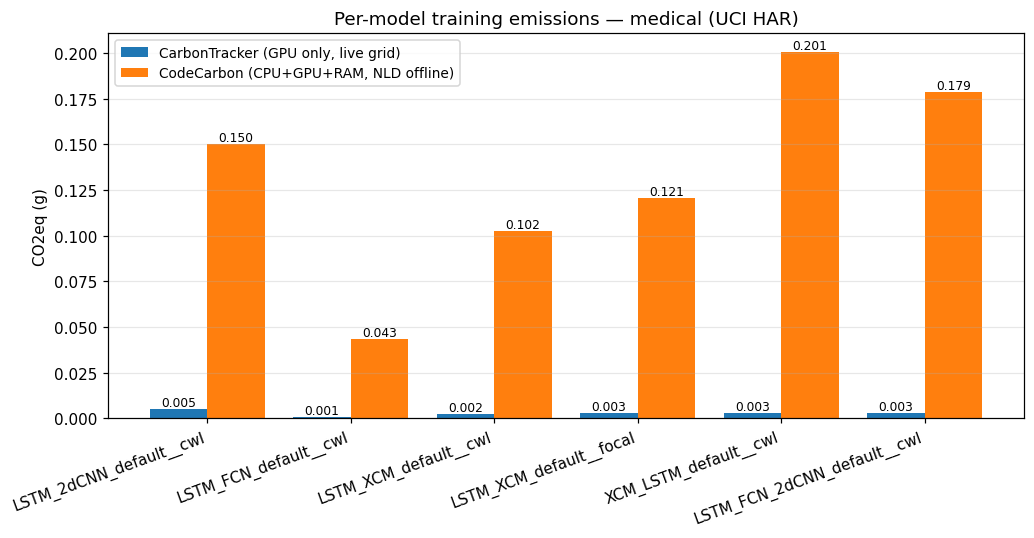

In [12]:
sub = df.set_index("run_label").reindex(RUN_LABELS).dropna(subset=["cc_emissions_g"], how="all")
xs = np.arange(len(sub)); w = 0.4
fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(sub)), 5))
ax.bar(xs - w/2, sub["ct_emissions_g"].fillna(0), w,
       label=f"CarbonTracker (GPU only, live grid)", color="#1f77b4")
ax.bar(xs + w/2, sub["cc_emissions_g"].fillna(0), w,
       label=f"CodeCarbon (CPU+GPU+RAM, {CARBON_COUNTRY_ISO3} offline)", color="#ff7f0e")
for x, v in zip(xs - w/2, sub["ct_emissions_g"].fillna(0)):
    ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
for x, v in zip(xs + w/2, sub["cc_emissions_g"].fillna(0)):
    ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(sub.index, rotation=20, ha="right")
ax.set_ylabel("CO2eq (g)"); ax.set_title("Per-model training emissions — medical (UCI HAR)")
ax.grid(axis="y", alpha=0.3); ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig("medical_per_model_emissions.png", bbox_inches="tight"); plt.show()

### 2. CodeCarbon energy breakdown — CPU / GPU / RAM

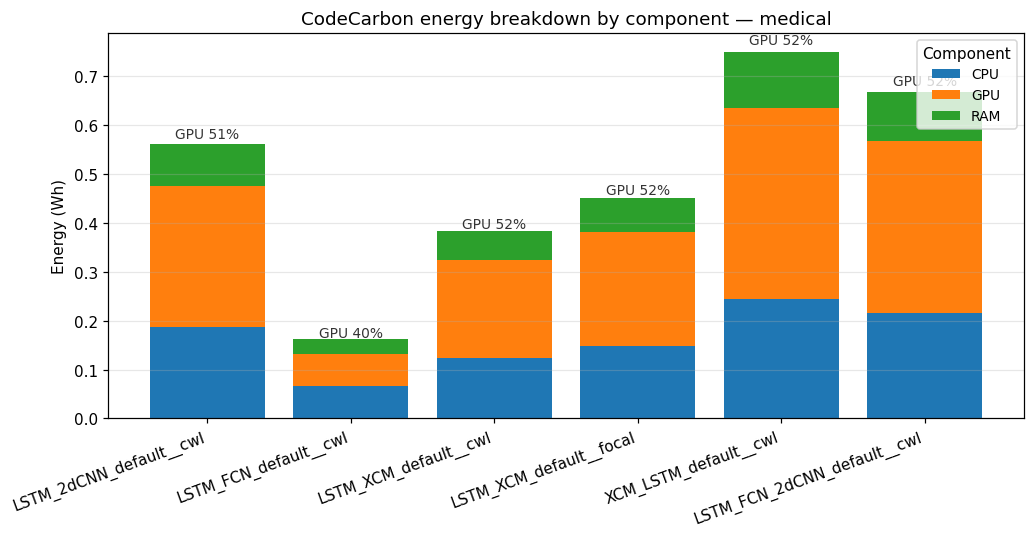

In [13]:
sub = df.set_index("run_label").reindex(RUN_LABELS).dropna(subset=["cc_energy_kwh"], how="all")
xs  = np.arange(len(sub))
cpu = (sub["cc_cpu_kwh"].fillna(0) * 1000).values
gpu = (sub["cc_gpu_kwh"].fillna(0) * 1000).values
ram = (sub["cc_ram_kwh"].fillna(0) * 1000).values
fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(sub)), 5))
ax.bar(xs, cpu,                   color="#1f77b4", label="CPU")
ax.bar(xs, gpu, bottom=cpu,       color="#ff7f0e", label="GPU")
ax.bar(xs, ram, bottom=cpu + gpu, color="#2ca02c", label="RAM")
totals = cpu + gpu + ram
for x, g, t in zip(xs, gpu, totals):
    if t > 0:
        ax.text(x, t * 1.02, f"GPU {100 * g / t:.0f}%", ha="center", fontsize=9, color="#333")
ax.set_xticks(xs); ax.set_xticklabels(sub.index, rotation=20, ha="right")
ax.set_ylabel("Energy (Wh)"); ax.set_title("CodeCarbon energy breakdown by component — medical")
ax.grid(axis="y", alpha=0.3); ax.legend(loc="upper right", fontsize=9, title="Component")
fig.tight_layout(); fig.savefig("medical_per_model_cc_breakdown.png", bbox_inches="tight"); plt.show()

### 3. Most carbon-efficient model

Ranked by **lowest CodeCarbon emissions** — top bar is greenest (winner in green).
`transition_recall` is printed alongside so efficiency can be weighed against quality.

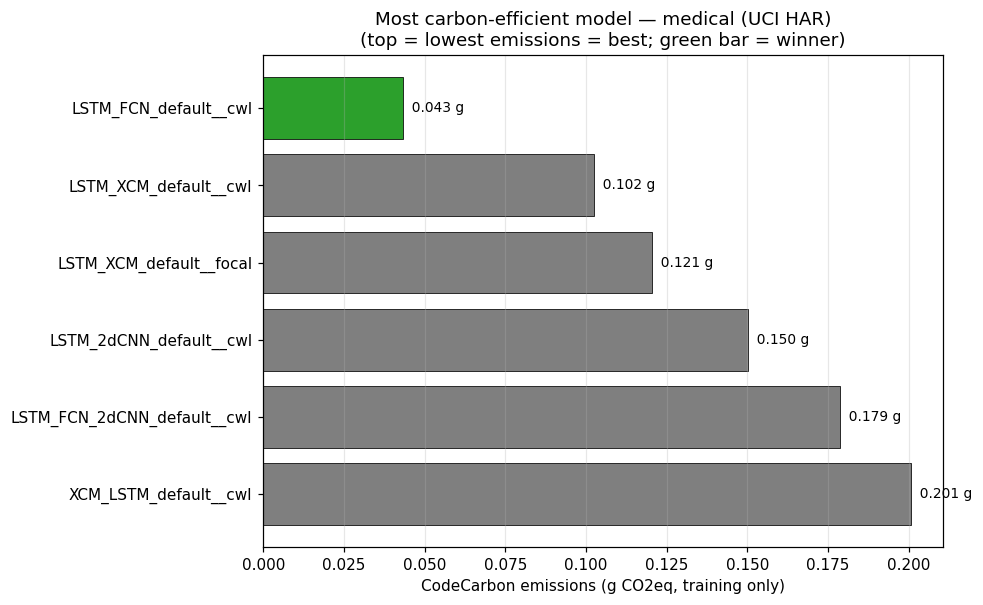


Carbon-efficiency podium (lowest emissions wins):
  BEST  LSTM_FCN_default__cwl         cc= 0.043 g  ct= 0.001 g  energy_cc=  0.16 Wh  transition_recall=0.892
    #2  LSTM_XCM_default__cwl         cc= 0.102 g  ct= 0.002 g  energy_cc=  0.38 Wh  transition_recall=0.820
    #3  LSTM_XCM_default__focal       cc= 0.121 g  ct= 0.003 g  energy_cc=  0.45 Wh  transition_recall=0.468
    #4  LSTM_2dCNN_default__cwl       cc= 0.150 g  ct= 0.005 g  energy_cc=  0.56 Wh  transition_recall=0.658
    #5  LSTM_FCN_2dCNN_default__cwl   cc= 0.179 g  ct= 0.003 g  energy_cc=  0.67 Wh  transition_recall=0.892
    #6  XCM_LSTM_default__cwl         cc= 0.201 g  ct= 0.003 g  energy_cc=  0.75 Wh  transition_recall=0.874


In [14]:
sub = (df.dropna(subset=["cc_emissions_g"])
         .sort_values("cc_emissions_g", ascending=True).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(9, max(3.5, 0.6 * len(sub) + 2)))
ys = np.arange(len(sub))
colors = ["#2ca02c"] + ["#7f7f7f"] * (len(sub) - 1)
ax.barh(ys, sub["cc_emissions_g"], color=colors, edgecolor="black", linewidth=0.5)
for y, val in zip(ys, sub["cc_emissions_g"]):
    ax.text(val, y, f"  {val:.3f} g", va="center", fontsize=9)
ax.set_yticks(ys); ax.set_yticklabels(sub["run_label"]); ax.invert_yaxis()
ax.set_xlabel("CodeCarbon emissions (g CO2eq, training only)")
ax.set_title("Most carbon-efficient model — medical (UCI HAR)\n"
             "(top = lowest emissions = best; green bar = winner)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout(); fig.savefig("medical_per_model_ranking.png", bbox_inches="tight"); plt.show()

print("\nCarbon-efficiency podium (lowest emissions wins):")
rank_tags = ["BEST", "  #2", "  #3", "  #4", "  #5", "  #6"]
for i, r in sub.iterrows():
    tag = rank_tags[min(i, len(rank_tags) - 1)]
    print(f"  {tag}  {r['run_label']:28s}  cc={r['cc_emissions_g']:6.3f} g  "
          f"ct={r.get('ct_emissions_g', float('nan')):6.3f} g  "
          f"energy_cc={r['cc_energy_kwh']*1000:6.2f} Wh  "
          f"transition_recall={r.get('transition_recall', float('nan')):.3f}")

### 4. Training vs evaluation emissions

Stacked CodeCarbon emissions per model: **training** (bottom) + **evaluation**
(top) = total job emissions. Training and eval are measured by two separate
CodeCarbon trackers, so the split is real, not estimated. The eval share is
labelled inside each bar — for these models it's typically tiny, which is the
usual justification for reporting training-only numbers in the charts above.

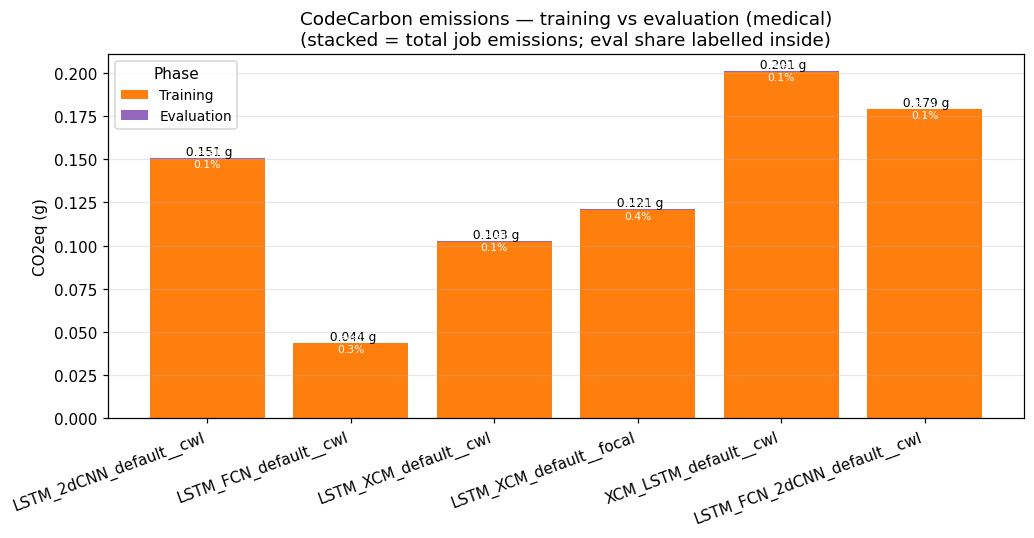

Across all models, evaluation is 0.1% of total (training+eval) CodeCarbon emissions.


In [15]:
sub = (df.set_index("run_label").reindex(RUN_LABELS)
         .dropna(subset=["cc_emissions_g", "cc_eval_emissions_g"], how="all"))
xs = np.arange(len(sub))
train_g = sub["cc_emissions_g"].fillna(0).values
eval_g  = (sub["cc_eval_emissions_g"].fillna(0).values
           if "cc_eval_emissions_g" in sub.columns else np.zeros(len(sub)))
totals  = train_g + eval_g

fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(sub)), 5))
ax.bar(xs, train_g, color="#ff7f0e", label="Training")
ax.bar(xs, eval_g, bottom=train_g, color="#9467bd", label="Evaluation")
for x, tr, ev, tot in zip(xs, train_g, eval_g, totals):
    if tot > 0:
        ax.text(x, tot, f" {tot:.3f} g", ha="center", va="bottom", fontsize=8)
        ax.text(x, tr + ev / 2, f"eval\n{100 * ev / tot:.1f}%",
                ha="center", va="center", fontsize=7, color="white")
ax.set_xticks(xs); ax.set_xticklabels(sub.index, rotation=20, ha="right")
ax.set_ylabel("CO2eq (g)")
ax.set_title("CodeCarbon emissions — training vs evaluation (medical)\n"
             "(stacked = total job emissions; eval share labelled inside)")
ax.grid(axis="y", alpha=0.3); ax.legend(loc="upper left", fontsize=9, title="Phase")
fig.tight_layout(); fig.savefig("medical_train_vs_eval_emissions.png", bbox_inches="tight"); plt.show()

eval_share = 100 * np.nansum(eval_g) / np.nansum(totals) if np.nansum(totals) > 0 else float("nan")
print(f"Across all models, evaluation is {eval_share:.1f}% of total (training+eval) CodeCarbon emissions.")

### 5. Numeric summary

In [19]:
SUMMARY_COLS = [c for c in [
    "run_label", "arch_label", "loss_type", "n_runs_aggregated", "total_params",
    "train_time_s", "eval_time_s", "ct_energy_kwh", "cc_energy_kwh",
    "cc_cpu_kwh", "cc_gpu_kwh", "cc_ram_kwh",
    "ct_emissions_g", "cc_emissions_g", "cc_eval_emissions_g", "cc_total_emissions_g",
    "tracker_spread_pct", "transition_recall", "f1_macro", "median_error",
] if c in df.columns]
summary = df[SUMMARY_COLS].sort_values("cc_emissions_g", ascending=True).reset_index(drop=True)
summary.to_csv("separate_medical_per_model_carbon_summary.csv", index=False)
print("Saved medical_per_model_carbon_summary.csv")
print("  cc_emissions_g = training | cc_eval_emissions_g = evaluation | cc_total_emissions_g = training + evaluation\n")
print(summary.round(4).to_string(index=False))

Saved medical_per_model_carbon_summary.csv
  cc_emissions_g = training | cc_eval_emissions_g = evaluation | cc_total_emissions_g = training + evaluation

                  run_label             arch_label loss_type  n_runs_aggregated  total_params  train_time_s  eval_time_s  ct_energy_kwh  cc_energy_kwh  cc_cpu_kwh  cc_gpu_kwh  cc_ram_kwh  ct_emissions_g  cc_emissions_g  cc_eval_emissions_g  cc_total_emissions_g  tracker_spread_pct  transition_recall  f1_macro  median_error
      LSTM_FCN_default__cwl       LSTM_FCN_default       cwl                  1      364835.0           5.0          0.0         0.0000         0.0002      0.0001      0.0001      0.0000          0.0008          0.0434               0.0001                0.0436            192.3423             0.8919    0.6591           0.0
      LSTM_XCM_default__cwl       LSTM_XCM_default       cwl                  1      266533.0          10.0          0.0         0.0000         0.0004      0.0001      0.0002      0.0001          

## Average inference time per sample

Average inference wall-time per test window (one 128-step sample), measured by
reloading each saved checkpoint and timing a clean forward pass over the whole
test set. This is independent of the logged `eval_time_s` (which is rounded to
whole seconds and is ~0 for sub-second medical inference). Lower = faster.

In [20]:
# Per-model inference latency: average wall-time per test sample (window).
ds_b, _ = _get_dataset()
N = ds_b["X_test"].shape[0]
REPEATS = 5
_lat_rows = []
for combo in CANONICAL_PLAN:
    ckpt = MODEL_DIR / f"{combo['run_name']}.pth"
    if not ckpt.exists():
        print("skip (no checkpoint):", combo["run_name"]); continue
    subset_idx, _ = resolve_subset(combo["subset_name"], ds_b["FEATURES_GEOX"])
    dls_b, _, _ = build_dataloader(ds_b, subset_idx, COMMON_RECIPE["batch_size"])
    arch_class, arch_kwargs = ARCH_REGISTRY[combo["arch_label"]]
    model = build_model(arch_class, dls=dls_b, **arch_kwargs)
    device = next(model.parameters()).device
    model.load_state_dict(torch.load(ckpt, map_location=device)); model.eval()
    X = torch.tensor(ds_b["X_test"][:, subset_idx, :], dtype=torch.float32).to(device)
    with torch.no_grad():                                    # warmup
        for _ in range(3): model(X[:64])
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        for _ in range(REPEATS):
            for i in range(0, N, 64): model(X[i:i+64])
    if torch.cuda.is_available(): torch.cuda.synchronize()
    per_sample_ms = (time.time() - t0) / (REPEATS * N) * 1000
    _lat_rows.append({"run_label": combo["run_label"], "n_test_samples": N,
                      "infer_ms_per_sample": per_sample_ms,
                      "samples_per_sec": 1000 / per_sample_ms})
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
lat = pd.DataFrame(_lat_rows).sort_values("infer_ms_per_sample").reset_index(drop=True)
lat.to_csv("separate_medical_inference_latency.csv", index=False)
print(f"Averaged over {REPEATS} passes of the {N}-sample test set. Saved medical_inference_latency.csv\n")
print(lat.round(4).to_string(index=False))

Averaged over 5 passes of the 277-sample test set. Saved medical_inference_latency.csv

                  run_label  n_test_samples  infer_ms_per_sample  samples_per_sec
      LSTM_FCN_default__cwl             277               0.0426       23463.9506
    LSTM_XCM_default__focal             277               0.0449       22269.9292
    LSTM_2dCNN_default__cwl             277               0.0450       22198.1904
      XCM_LSTM_default__cwl             277               0.0472       21204.3855
      LSTM_XCM_default__cwl             277               0.0481       20785.5010
LSTM_FCN_2dCNN_default__cwl             277               0.0575       17399.7371


### Per-sample inference energy & CO₂

Only meaningful when inference is tracked on its own (the `_separate` notebook).
The `_combined` notebook fuses training and inference energy, so this prints a
notice there instead.

In [21]:
# Per-sample inference energy / CO2 (separate-tracking notebooks only).
if "cc_eval_emissions_g" in df.columns:
    N = _get_dataset()[0]["X_test"].shape[0]
    perf = df[["run_label"]].copy()
    perf["infer_uJ_per_sample"]    = df["cc_eval_energy_kwh"] * 3.6e9 / N    # micro-joules / sample
    perf["infer_mgCO2_per_sample"] = df["cc_eval_emissions_g"] * 1000 / N    # mg CO2eq / sample
    print(f"Per-sample inference cost (N={N} test samples):\n")
    print(perf.round(4).to_string(index=False))
else:
    print("Inference energy is not isolated in this (combined) notebook — per-sample "
          "inference energy/CO2 is only available in the _separate notebook.")

Per-sample inference cost (N=277 test samples):

                  run_label  infer_uJ_per_sample  infer_mgCO2_per_sample
    LSTM_2dCNN_default__cwl               7.0957                  0.0005
      LSTM_FCN_default__cwl               6.0388                  0.0004
      LSTM_XCM_default__cwl               6.6868                  0.0005
    LSTM_XCM_default__focal              22.5018                  0.0017
      XCM_LSTM_default__cwl               6.7937                  0.0005
LSTM_FCN_2dCNN_default__cwl               6.8982                  0.0005
